# 02b Estimate: linear regression, Ridge and Lasso on the series' own past

The (S)ARIMA models of `02_estimate.ipynb` are one way to forecast from the past of the series. In the present notebook, we try another: **regression models**, where we choose ourselves which pieces of the past go in as features: the recent changes, the same change one year earlier and the calendar month. Regressions are easy to explain, and they let us add other information later, such as the route indicator in `02c_estimate_indicator.ipynb`. We try three versions: a plain linear regression and two penalised versions, Ridge and Lasso.

To compare them fairly with the models of `02_estimate.ipynb`, we use exactly the same backtest: the same forecast origins, the same horizons and the same rules. We read the clean series from `01_preprocess.ipynb` (`../data/processed/asylum_clean.csv`). We save the forecasts in `../data/processed/backtest_forecasts_regression.csv`, with the same columns as `backtest_forecasts.csv` plus the chosen penalty, and one figure in `../output/figures/`.

As in `02_estimate.ipynb`, the test period (October 2024 to September 2026) is not used, so that it stays a fair check at the end. We compare all models in `03_evaluate.ipynb`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso

np.random.seed(42)
plt.style.use("seaborn-v0_8-muted")

## 1. Load the clean data

We load the same data and use the same forecast origins as in `02_estimate.ipynb`: the first origin is December 2012 and the last backtest month is September 2024. Using the same origins is what makes the comparison fair: every model will be scored on exactly the same months.

In [2]:
clean = pd.read_csv("../data/processed/asylum_clean.csv")
clean["month"] = pd.to_datetime(clean["month"])
clean = clean.set_index("month")

y = clean["applicants_total"].to_numpy(dtype=float)     # applications in persons
log_y = clean["log_applicants"].to_numpy(dtype=float)   # log of applications
months = clean.index

FIRST_ORIGIN = pd.Timestamp("2012-12-01")
LAST_BACKTEST = pd.Timestamp("2024-09-01")
H_MAX = 3

first_origin = int(np.where(months == FIRST_ORIGIN)[0][0])
last_backtest = int(np.where(months == LAST_BACKTEST)[0][0])
print("First origin:", months[first_origin], "| last backtest month:", months[last_backtest])

First origin: 2012-12-01 00:00:00 | last backtest month: 2024-09-01 00:00:00


## 2. From SARIMA to a regression: what we predict and with what

A SARIMA model forecasts several months ahead by itself (`.forecast(steps=3)`). A regression does not: it needs a target $y$ and features $x$, so we have to say exactly what we predict, and from what.

Let's start with what we predict. In `01_preprocess.ipynb`, the ADF test showed that the log series is not stationary but its changes are; this is why the SARIMA models use one difference ($d = 1$). We follow the same idea and let the regression predict the **change of the log of applications** between the origin month $t$ and the forecast month $t+h$,

$$\Delta_h = \log y_{t+h} - \log y_t ,$$

which is roughly the percentage change (an error of 0.10 in logs is about 10% off). Predicting a change rather than a level means the model starts from the last known month and only has to say how much it will move. The forecast in logs is then $\log y_t + \widehat{\Delta}_h$, and in applications $\exp(\log y_t + \widehat{\Delta}_h)$.

Next, the features. They come from what we found in `01_preprocess.ipynb`: the ACF showed a dependence on the last months and on the same month one year earlier, and the series has a clear calendar pattern. So the features are:

| Feature | Formula | Idea |
|---|---|---|
| `change_last_month` | $\log y_t - \log y_{t-1}$ | the most recent monthly change |
| `change_month_before` | $\log y_{t-1} - \log y_{t-2}$ | the change one month earlier |
| `same_change_last_year` | $\log y_{t+h-12} - \log y_{t-12}$ | how the same months moved one year earlier (the idea of a seasonal difference) |
| `month_2`, ..., `month_12` | 0/1 | the calendar month of the forecast month, as dummies with one month left out (`drop_first=True`) |

We leave one month out of the dummies (January) because otherwise the dummies would always add up to one and repeat the constant of the regression. For $h \le 3$, every value used here is from month $t$ or earlier, so it is known at the cutoff: no feature looks into the future.

*Not seen in class:* **one regression per horizon** (a "direct" forecast). A regression gives one number per row, so we train a separate model for $h = 1$, $h = 2$ and $h = 3$; in each one, the target is the change $h$ months ahead.

## 3. Build one table per horizon

For each horizon $h$, we build a table with **one row per possible origin** $t$: the features known at $t$ and the target $\Delta_h$. The first row is $t = 12$ (January 2009), the first origin for which the value 12 months earlier exists. The row number is the position of the origin month in the data. This makes it easy later to select "all rows up to an origin", which is exactly what an honest backtest needs.

*Not seen in class:* `months[t + h].month` gives the calendar month (1 to 12) of a date.

In [3]:
def make_table(h):
    # One row per origin t: features known at t, target = change of log applications h months ahead
    rows = []
    for t in range(12, len(log_y) - h):
        rows.append({
            "t": t,
            "change_last_month": log_y[t] - log_y[t - 1],
            "change_month_before": log_y[t - 1] - log_y[t - 2],
            "same_change_last_year": log_y[t + h - 12] - log_y[t - 12],
            "calendar_month": months[t + h].month,
            "target": log_y[t + h] - log_y[t],
        })
    table = pd.DataFrame(rows).set_index("t")

    # Calendar month of the forecast month as dummies, one month left out
    dummies = pd.get_dummies(table["calendar_month"], prefix="month", drop_first=True).astype(float)
    X = pd.concat([table[["change_last_month", "change_month_before", "same_change_last_year"]], dummies], axis=1)
    return X, table["target"]

tables = {h: make_table(h) for h in range(1, H_MAX + 1)}

X2, target2 = tables[2]
print("Table for h = 2:", X2.shape[0], "rows (origins) and", X2.shape[1], "features")
print("Missing values:", X2.isna().sum().sum(), "|", target2.isna().sum())
X2.head()

Table for h = 2: 211 rows (origins) and 14 features
Missing values: 0 | 0


,change_last_month,change_month_before,same_change_last_year,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12
t,,,,,,,,,,,,,,
12,0.082806,0.014493,-0.176624,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
13,-0.506420,0.082806,0.232403,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
14,-0.041127,-0.506420,0.022473,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
15,-0.087706,-0.041127,0.075424,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
16,-0.119347,-0.087706,0.196115,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


As we can see, for $h = 2$ the table has 211 rows (one per possible origin) and 14 features: the three changes and 11 month dummies. No value is missing. In the first row ($t = 12$, January 2009), the dummy `month_3` is 1, because the forecast month two months later is March.

So the table is built as intended, with every feature known at its origin, so we can now define the models.

## 4. The three candidates

All three are linear models on the same 14 features; they differ only in how strongly they hold their coefficients back. The **linear regression** has no penalty and serves as a reference. **Ridge** penalises the squared size of the coefficients, which shrinks them all a little and makes the model less sensitive to noise in the training data. **Lasso** penalises their absolute size and can set some of them exactly to zero, which removes features that do not help. With 14 features and a few dozen to a few hundred training months, such penalties could help the model avoid fitting noise.

Ridge and Lasso penalise all coefficients alike, so the features must be on the same scale; otherwise a feature measured in large numbers would be penalised differently from one measured in small numbers. `make_pipeline(StandardScaler(), ...)` keeps the scaler and the model together: the scaler is fitted on the training rows only, every time the model is fitted, so it never uses information from later months.

The strength of the penalty, `alpha`, is chosen from a grid of values. In a first trial, the chosen `alpha` often sat at the edge of a smaller grid; a value at the edge means the best one may lie outside the grid, so we use these wider grids. That first trial ran on the backtest, so the grids themselves were set with some knowledge of the backtest years. The test period was not used.

In [4]:
def make_model(name, alpha=None):
    if name == "Linear regression":
        return make_pipeline(StandardScaler(), LinearRegression())
    if name == "Ridge":
        return make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    return make_pipeline(StandardScaler(), Lasso(alpha=alpha, max_iter=10000))

alpha_grids = {
    "Linear regression": [None],                                # no penalty, nothing to choose
    "Ridge": [0.1, 1, 10, 100, 1000, 10000],
    "Lasso": [0.0001, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3],
}

## 5. Choosing the penalty inside each training window

At every forecast origin, we must choose `alpha` using only the rows of that training window; the backtest months after the origin stay unseen, because everything that learns from the data must stay inside the training window. A random K-fold split would mix later months into the training data, which a planner could never do. So we use small expanding windows inside the training window.

At origin $T$, the training rows are the origins $t \le T - h$, because only their target month $t + h$ is already known at $T$. The last 24 of these rows form two validation blocks of 12 months; we use blocks of 12 months so that each block covers every calendar month once and no season is favoured. For a validation block that starts at row $s$, the model is fitted on the rows $t \le s - h$ only, so that no training target lies after the start of the block. For each `alpha`, we average the mean squared error (in logs) over the two blocks and keep the `alpha` with the lowest value. Note that this is not the measure we use later to compare the models, the MAE in applications. We use the squared error in logs here because it is the error the regression itself minimises.

We chose two blocks, not three, before running the backtest. At the first origin, three blocks would leave only 7 training rows for 14 features in the first block, too few to fit the model; two blocks leave 19.

In [5]:
def choose_alpha(name, X, target, T, h, n_blocks=2, block=12):
    grid = alpha_grids[name]
    if len(grid) == 1:
        return grid[0]
    first_row, last_row = X.index.min(), T - h
    scores = []
    for alpha in grid:
        mse_blocks = []
        for b in range(n_blocks):
            start = last_row - n_blocks * block + 1 + b * block   # first row of the validation block
            valid_rows = list(range(start, start + block))
            train_rows = list(range(first_row, start - h + 1))    # targets known before the block starts
            model = make_model(name, alpha).fit(X.loc[train_rows], target.loc[train_rows])
            errors = target.loc[valid_rows].to_numpy() - model.predict(X.loc[valid_rows])
            mse_blocks.append(np.mean(errors ** 2))
        scores.append(np.mean(mse_blocks))
    return grid[int(np.argmin(scores))]

### A first check at the first origin

As in `02_estimate.ipynb`, before running the whole backtest we check that the code does what we expect at one origin, December 2012. We compare the forecasts, transformed back to applications, with the actual numbers of January to March 2013. This is a sanity check, not an evaluation.

In [6]:
t = first_origin
check = pd.DataFrame(index=months[t + 1: t + 1 + H_MAX])
check.index.name = "forecast month"
check["Actual"] = y[t + 1: t + 1 + H_MAX]

for name in alpha_grids:
    values = []
    for h in range(1, H_MAX + 1):
        X, target = tables[h]
        train_rows = list(range(X.index.min(), t - h + 1))
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            alpha = choose_alpha(name, X, target, t, h)
            model = make_model(name, alpha).fit(X.loc[train_rows], target.loc[train_rows])
        change = model.predict(X.loc[[t]])[0]
        values.append(np.exp(log_y[t] + change))
    check[name] = np.round(values, 0)

print("Training rows at the first origin for h = 1:", t - 1 - tables[1][0].index.min() + 1)
check

Training rows at the first origin for h = 1: 47


,Actual,Linear regression,Ridge,Lasso
forecast month,,,,
2013-01-01,2140.0,2280.0,1880.0,1871.0
2013-02-01,1795.0,1474.0,1509.0,1491.0
2013-03-01,1825.0,1939.0,1729.0,1806.0


The output shows that, at the first origin, the models are fitted on 47 rows for $h = 1$. The actual numbers for January to March 2013 were 2,140, 1,795 and 1,825. The forecasts lie between about 1,470 and 2,280: the linear regression is too high in January (2,280) and too low in February (1,474), while Ridge and Lasso are below the actual numbers in all three months.

So the code runs and the forecasts are in a plausible range. One origin says nothing about which model is better, so we now run the whole backtest.

## 6. The backtest loop

The loop works exactly as in `02_estimate.ipynb`. For each origin from December 2012 to August 2024, and each horizon, we choose `alpha` inside the training window, fit the model on all training rows ($t \le T - h$), and forecast the change from the origin. Inside the loop, the training rows are built so that their target month is already known at the origin: only origins up to $t - h$. An `assert` repeats this rule. It cannot fail with the code as it is, but it would stop the code if a later change broke the rule. Lasso sometimes warns that it has not fully converged when `alpha` is very small; we hide these warnings, as in `02_estimate.ipynb`, and check the forecasts afterwards.

For each origin and horizon, the loop fits 1 linear regression, 13 Ridge models (6 values of `alpha` in 2 blocks, then the final fit) and 15 Lasso models: about 12,000 small models, which takes one to two minutes.

In [7]:
rows = []

for t in range(first_origin, last_backtest):              # t = position of the forecast origin
    for h in range(1, H_MAX + 1):
        target_pos = t + h
        if target_pos > last_backtest:                     # never forecast into the test period
            continue
        X, target = tables[h]
        train_rows = list(range(X.index.min(), t - h + 1))  # all origins whose target is known at t
        assert max(train_rows) + h <= t                    # no training target after the origin

        for name in alpha_grids:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                alpha = choose_alpha(name, X, target, t, h)
                model = make_model(name, alpha).fit(X.loc[train_rows], target.loc[train_rows])
            forecast_log = log_y[t] + model.predict(X.loc[[t]])[0]
            rows.append({
                "model": name,
                "origin": months[t],
                "month": months[target_pos],
                "h": h,
                "forecast_log": forecast_log,
                "actual_log": log_y[target_pos],
                "forecast": np.exp(forecast_log),
                "actual": y[target_pos],
                "alpha": alpha,
            })

forecasts = pd.DataFrame(rows)
print("Number of stored forecasts:", forecasts.shape[0])
forecasts.head()

Number of stored forecasts: 1260


,model,origin,month,h,forecast_log,actual_log,forecast,actual,alpha
0,Linear regression,2012-12-01,2013-01-01,1,7.732130,7.668561,2280.454521,2140.0,NaN
1,Ridge,2012-12-01,2013-01-01,1,7.539144,7.668561,1880.220608,2140.0,10.00
2,Lasso,2012-12-01,2013-01-01,1,7.534323,7.668561,1871.176800,2140.0,0.01
3,Linear regression,2012-12-01,2013-02-01,2,7.295728,7.492760,1473.988926,1795.0,NaN
4,Ridge,2012-12-01,2013-02-01,2,7.319342,7.492760,1509.210411,1795.0,10.00


## 7. Checks on the stored forecasts

We run the same checks as in `02_estimate.ipynb`, for the same reasons. The number of forecasts per model and horizon must be 141, 140 and 139, so that the regressions are scored on exactly the same months as the other models. No forecast month may lie in the test period, every forecast month must lie after its origin, and no value may be missing.

In [8]:
print("Number of forecasts per model and horizon:")
print(forecasts.groupby(["model", "h"]).size())

Number of forecasts per model and horizon:
model              h
Lasso              1    141
                   2    140
                   3    139
Linear regression  1    141
                   2    140
                   3    139
Ridge              1    141
                   2    140
                   3    139
dtype: int64


In [9]:
print("Last forecast month:", forecasts["month"].max())
print("All forecast months in the backtest (before 2024-10):", (forecasts["month"] < pd.Timestamp("2024-10-01")).all())
print("All forecast months after their origin:", (forecasts["month"] > forecasts["origin"]).all())
print("Missing or infinite forecasts:", (~np.isfinite(forecasts["forecast_log"])).sum())

Last forecast month: 2024-09-01 00:00:00
All forecast months in the backtest (before 2024-10): True
All forecast months after their origin: True
Missing or infinite forecasts: 0


The checks show that every model has 141 forecasts for $h = 1$, 140 for $h = 2$ and 139 for $h = 3$, together 1,260 forecasts. The last forecast month is September 2024, every forecast month lies after its origin, and no forecast is missing.

This matters because the regressions must be compared with the other models on exactly the same months. That they use only data known at each origin follows from how the training rows are built (section 6).

### Which penalties were chosen?

The chosen value of `alpha` should lie *inside* the grid. If it often sits at an edge, the best value may lie outside the grid, and the grid should be extended. So we count how often each `alpha` was chosen, over all origins and horizons together.

In [10]:
for name in ["Ridge", "Lasso"]:
    chosen = forecasts.loc[forecasts["model"] == name, "alpha"]
    print(f"{name}: how often each alpha was chosen (grid from {alpha_grids[name][0]} to {alpha_grids[name][-1]})")
    print(chosen.value_counts().sort_index().to_string())
    print()

Ridge: how often each alpha was chosen (grid from 0.1 to 10000)
alpha
0.1         94
1.0          8
10.0        48
100.0      207
1000.0      59
10000.0      4

Lasso: how often each alpha was chosen (grid from 0.0001 to 0.3)
alpha
0.0001     82
0.0010     21
0.0030     21
0.0100    106
0.0300    109
0.1000     54
0.3000     27



Looking at the chosen penalties, **Ridge** most often chose `alpha = 100` (207 of 420 times). The largest value (10,000) was chosen only 4 times, and the smallest value (0.1) 94 times. **Lasso** most often chose 0.01 and 0.03 (106 and 109 times). The smallest value (0.0001) was chosen 82 times, the largest (0.3) 27 times.

This tells us that the upper edge of the grids is rarely reached, so the grids are wide enough on that side. The lower edge is reached more often, but it means *almost no penalty*: there, Ridge and Lasso become a plain linear regression, which is already one of our three candidates. So we do not need to extend the grids further down.

## 8. Which inputs matter? The coefficients at the last origin

A model we cannot explain is hard to trust, so we look at what the models have learned. We fit Ridge and Lasso for $h = 2$ at the last origin (August 2024), with the `alpha` chosen there, and print their coefficients. Because the features are standardised, the coefficients are on the same scale and can be compared with each other. Lasso may set some of them exactly to zero.

We have to be careful here: these coefficients describe what helps to *predict* the change, not what *causes* it. Our project is a prediction task, not a causal analysis, as the project brief requires.

In [11]:
t = last_backtest - 1
h = 2
X, target = tables[h]
train_rows = list(range(X.index.min(), t - h + 1))

coefficients = pd.DataFrame(index=X.columns)
for name in ["Ridge", "Lasso"]:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        alpha = choose_alpha(name, X, target, t, h)
        model = make_model(name, alpha).fit(X.loc[train_rows], target.loc[train_rows])
    coefficients[f"{name} (alpha = {alpha})"] = model[-1].coef_     # the last step of the pipeline is the model

print("Origin:", months[t], "| horizon h =", h, "| training rows:", len(train_rows))
coefficients.round(3)

Origin: 2024-08-01 00:00:00 | horizon h = 2 | training rows: 186


,Ridge (alpha = 0.1),Lasso (alpha = 0.0001)
change_last_month,-0.016,-0.016
change_month_before,-0.027,-0.026
same_change_last_year,0.005,0.005
month_2,-0.009,-0.009
month_3,-0.026,-0.026
month_4,-0.009,-0.009
month_5,0.005,0.005
month_6,0.079,0.079
month_7,0.080,0.080
month_8,0.060,0.060


As we can see, at the last origin both models chose their smallest `alpha` (0.1 and 0.0001), so they are almost a plain linear regression and their coefficients are nearly the same. The largest coefficients are the month dummies for June, July and August (0.079, 0.080 and 0.060), and they stay positive up to November: compared with January, the month left out, applications tend to rise when we forecast into summer and autumn. The two recent changes have small negative coefficients (−0.016 and −0.027): after a rise, the next change tends to be a little smaller, so part of a recent jump tends to reverse. `same_change_last_year` is close to zero (0.005): once the calendar months are in the model, last year's change adds almost nothing. These coefficients are on standardised features, so they are not percentages: they only let us compare the features with each other.

So the models mainly learn the seasonal pattern and a small reversal of recent jumps, which is easy to explain to a planner. These numbers describe what helps to *predict*, not what *causes* applications to change.

## 9. A first look: forecasts at the main horizon ($h = 2$)

As in `02_estimate.ipynb`, we plot the forecasts two months ahead against the actual numbers, to see how the regressions behave, for example at turning points. The errors themselves are computed in `03_evaluate.ipynb`.

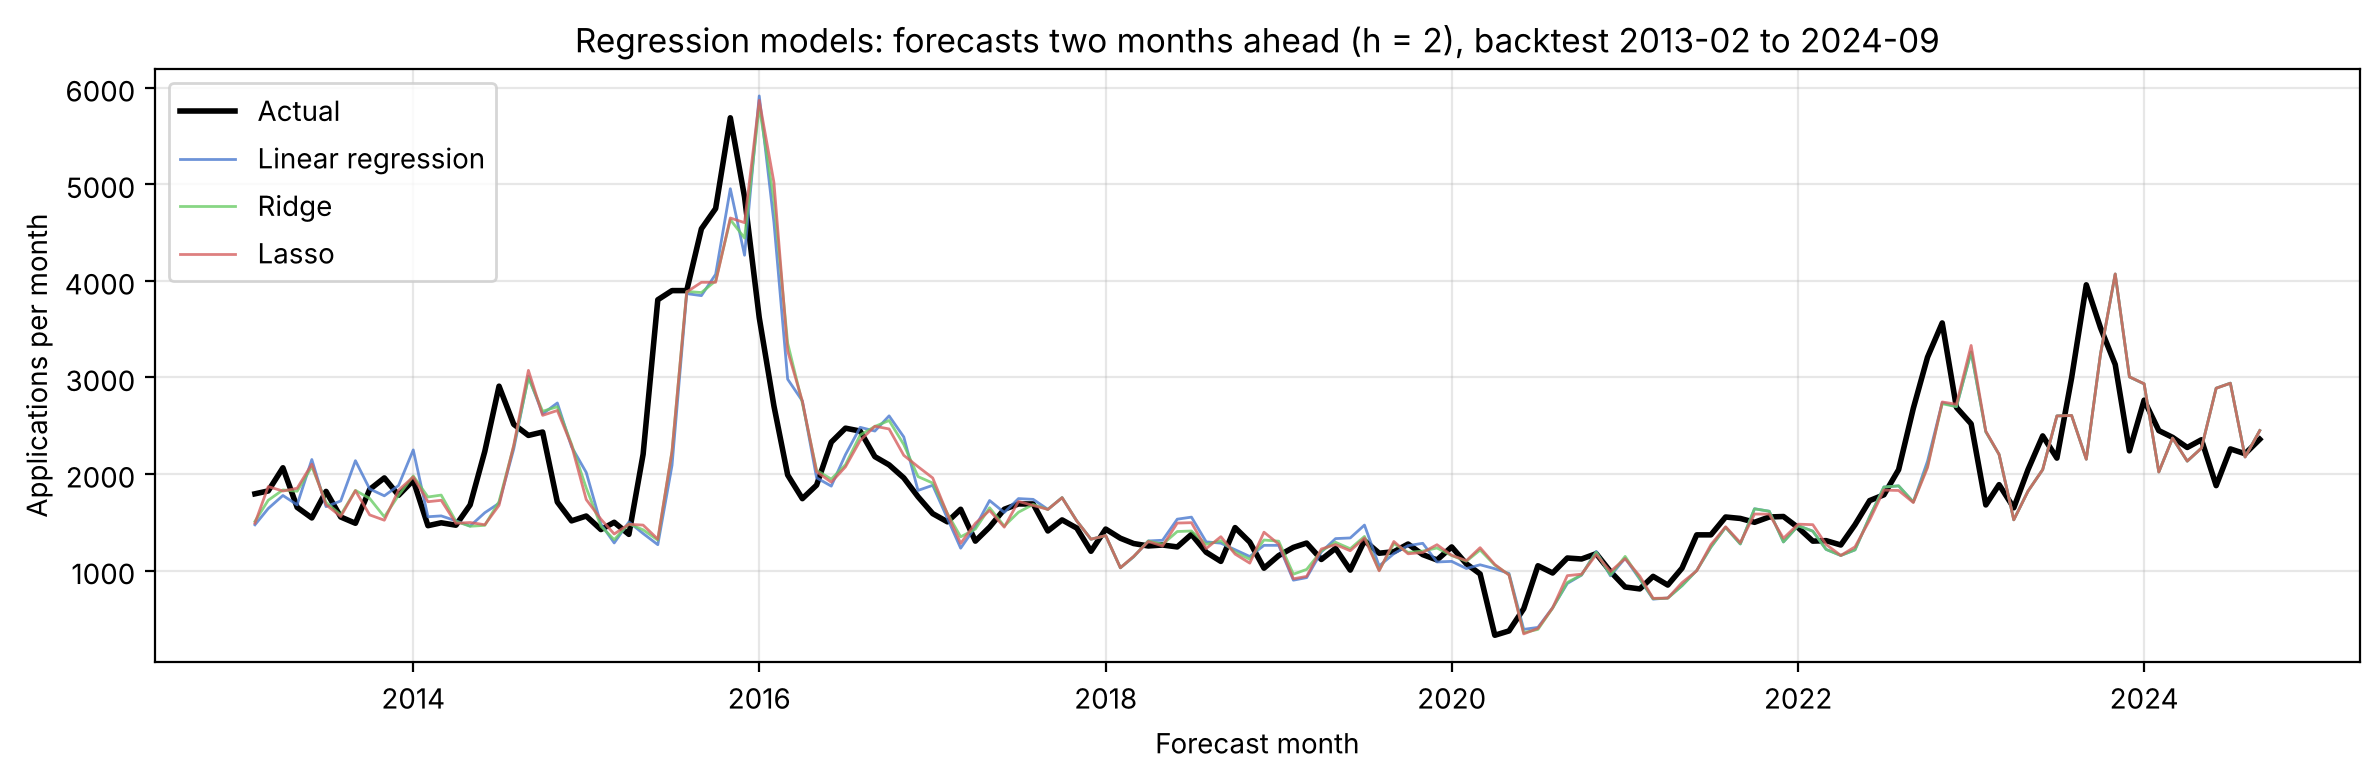

In [12]:
h2 = forecasts[forecasts["h"] == 2]
actual = h2[h2["model"] == "Linear regression"].set_index("month")["actual"]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(actual.index, actual, color="black", linewidth=2, label="Actual")
for name in ["Linear regression", "Ridge", "Lasso"]:
    one = h2[h2["model"] == name].set_index("month")["forecast"]
    ax.plot(one.index, one, linewidth=1, alpha=0.8, label=name)
ax.set_title("Regression models: forecasts two months ahead (h = 2), backtest 2013-02 to 2024-09")
ax.set_xlabel("Forecast month")
ax.set_ylabel("Applications per month")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/02b_backtest_forecasts_regression_h2.png")
plt.show()

In the plot, the three regression models give almost the same forecasts: their lines lie nearly on top of each other. Like the (S)ARIMA models in `02_estimate.ipynb`, they follow the actual curve with a delay. After the peak of late 2015, they forecast close to 6,000 at the start of 2016, when the actual numbers were already falling; they did not foresee the drop of spring 2020; and their peak of late 2023 comes after the actual one.

This shows that a regression on the series' own past cannot see sudden changes coming either, because it only reacts once a change shows in the data. Whether it is better than SARIMA on average, we measure in `03_evaluate.ipynb`.

## 10. Save the forecasts

We save all forecasts, with the chosen `alpha`, so that `03_evaluate.ipynb` can compare them with the models of `02_estimate.ipynb` on exactly the same months.

In [13]:
forecasts.to_csv("../data/processed/backtest_forecasts_regression.csv", index=False)
print("Saved", forecasts.shape[0], "forecasts with the columns", list(forecasts.columns))

Saved 1260 forecasts with the columns ['model', 'origin', 'month', 'h', 'forecast_log', 'actual_log', 'forecast', 'actual', 'alpha']


## Summary

In this notebook, we built three regressions on the series' own past: a linear regression, Ridge and Lasso, with one model per horizon. They predict the change of log applications from the recent changes, the same change one year earlier and the calendar month. They mainly learn the seasonal pattern and a small reversal of recent jumps. Like the SARIMA models, however, they are late at turning points, because they only use the past of the series.

The regressions follow the same honest rules as the other models. We use the same 141 origins and the same horizons as `02_estimate.ipynb`. Scaling and the choice of `alpha` happen inside each training window only, with two validation blocks of 12 months, and an `assert` checks that no training target lies after the origin.

*Not seen in class (marked above):* one regression per horizon ("direct" forecasts); `months[t + h].month`.

The 1,260 forecasts are saved in `../data/processed/backtest_forecasts_regression.csv` and compared with all other models in `03_evaluate.ipynb`.